In [1]:
!pip install -q underthesea pyvi

In [2]:
!pip install -q nltk pycocoevalcap

In [21]:
!pip install -q -U sentence-transformers

# Xử lý dữ liệu và tokenizer tiếng Việt

Hàm đọc và tải dữ liệu

In [3]:
import os
import json

DATA_DIR = "/kaggle/input/datasets/bactx1607/uit-viic"

TRAIN_JSON = os.path.join(
    DATA_DIR, "uitviic_captions_train2017.json"
)

VAL_JSON = os.path.join(
    DATA_DIR, "uitviic_captions_val2017.json"
)

TEST_JSON = os.path.join(
    DATA_DIR, "uitviic_captions_test2017.json"
)

def load_dataset(json_path):

    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    images = data["images"]
    annotations = data["annotations"]

    return images, annotations


train_images, train_annotations = load_dataset(TRAIN_JSON)
val_images, val_annotations = load_dataset(VAL_JSON)
test_images, test_annotations = load_dataset(TEST_JSON)

Thống kê và in ra thông số cơ bản

In [4]:
def dataset_statistics(images, annotations, name):

    print(f"\n===== {name} =====")

    print("Số lượng ảnh:", len(images))
    print("Số lượng caption:", len(annotations))

    captions_per_image = len(annotations) / len(images)

    print(
        "Số caption trung bình mỗi ảnh:",
        round(captions_per_image, 2)
    )


dataset_statistics(train_images, train_annotations, "TRAIN")
dataset_statistics(val_images, val_annotations, "VALIDATION")
dataset_statistics(test_images, test_annotations, "TEST")


===== TRAIN =====
Số lượng ảnh: 2695
Số lượng caption: 13481
Số caption trung bình mỗi ảnh: 5.0

===== VALIDATION =====
Số lượng ảnh: 924
Số lượng caption: 4620
Số caption trung bình mỗi ảnh: 5.0

===== TEST =====
Số lượng ảnh: 231
Số lượng caption: 1155
Số caption trung bình mỗi ảnh: 5.0


**Xây dựng tokenizer tiếng việt**

Tiền xử lý(làm sạch và chuẩn hóa) tiếng Việt = pyvi

In [5]:
import re
import unicodedata
from pyvi import ViTokenizer

def preprocess_caption(caption):
    # Chuẩn hóa Unicode
    caption = unicodedata.normalize("NFC", caption)

    # Chuyển về chữ thường
    caption = caption.lower()

    # Chuẩn hóa khoảng trắng
    caption = re.sub(r"\s+", " ", caption).strip()

    # Tách từ tiếng Việt
    caption = ViTokenizer.tokenize(caption)

    return caption

Xây dựng từ điển (Chuyển các từ thành id để máy tính có thể hiểu được)

In [6]:
from collections import Counter
import json

class VietnameseTokenizer:

    def __init__(self, min_freq=1):
        self.min_freq = min_freq

        self.special_tokens = [
            "<pad>",
            "<unk>",
            "<start>",
            "<end>"
        ]

        self.word2idx = {}    #từ -> số
        self.idx2word = {}    #số -> từ

    def build_vocab(self, captions):
        # Đếm tần suất xuất hiện của từng từ
        counter = Counter()

        for caption in captions:
            tokens = preprocess_caption(caption)
            counter.update(tokens.split())

        # Khởi tạo từ điển bằng các token đặc biệt
        self.word2idx = {
            token: idx
            for idx, token in enumerate(self.special_tokens)
        }

        # Thêm các từ xuất hiện đủ số lần
        for word, freq in counter.items():
            if freq >= self.min_freq:
                if word not in self.word2idx:
                    self.word2idx[word] = len(self.word2idx)

        self.idx2word = {
            idx: word
            for word, idx in self.word2idx.items()
        }

        print("Vocabulary size:", len(self.word2idx))

    def encode(self, caption):

        tokens = preprocess_caption(caption).split()

        ids = [self.word2idx["<start>"]]

        for token in tokens:
            ids.append(
                self.word2idx.get(
                    token,
                    self.word2idx["<unk>"]
                )
            )

        ids.append(self.word2idx["<end>"])

        return ids

    def decode(self, ids):

        tokens = []

        for idx in ids:
            word = self.idx2word.get(idx, "<unk>")

            if word == "<end>":
                break

            if word not in ["<pad>", "<start>"]:
                tokens.append(word)

        return " ".join(tokens)

    def save_vocab(self, path):

        with open(path, "w", encoding="utf-8") as f:
            json.dump(
                self.word2idx,
                f,
                ensure_ascii=False,
                indent=4
            )

Chạy thử và lưu từ điển

In [7]:
# train_captions là danh sách caption tiếng Việt
# được lấy từ tập train của UIT-ViIC
train_captions = [
    annotation["caption"]
    for annotation in train_annotations
]

tokenizer = VietnameseTokenizer(min_freq=1)
tokenizer.build_vocab(train_captions)

# Thử mã hóa một caption
caption = train_captions[0]

encoded = tokenizer.encode(caption)

print("Caption gốc:", caption)
print("Caption đã mã hóa:", encoded)

# Thử giải mã
decoded = tokenizer.decode(encoded)

print("Caption sau giải mã:", decoded)

# Lưu từ điển
tokenizer.save_vocab("/kaggle/working/vocab.json")

Vocabulary size: 1317
Caption gốc: Người đàn ông đang đánh tennis ngoài sân.
Caption đã mã hóa: [2, 4, 5, 6, 7, 8, 9, 10, 11, 3]
Caption sau giải mã: người đàn_ông đang đánh tennis ngoài sân .


Ghép ảnh và caption thành 1 cặp

In [8]:
def create_image_caption_pairs(images, annotations):

    image_dict = {
        image["id"]: image["file_name"]
        for image in images
    }

    pairs = []

    for annotation in annotations:

        image_id = annotation["image_id"]

        if image_id in image_dict:

            pairs.append({
                "image_id": image_id,
                "image": image_dict[image_id],
                "caption": annotation["caption"]
            })

    return pairs


train_pairs = create_image_caption_pairs(
    train_images, train_annotations
)

val_pairs = create_image_caption_pairs(
    val_images, val_annotations
)

test_pairs = create_image_caption_pairs(
    test_images, test_annotations
)

Lưu dữ liệu

In [9]:
import json

def save_pairs(pairs, filename):

    with open(filename, "w", encoding="utf-8") as f:
        json.dump(
            pairs,
            f,
            ensure_ascii=False,
            indent=4
        )


save_pairs(train_pairs, "/kaggle/working/train_pairs.json")
save_pairs(val_pairs, "/kaggle/working/val_pairs.json")
save_pairs(test_pairs, "/kaggle/working/test_pairs.json")

Tải ảnh từ bộ dữ liệu

In [10]:
import os
import json
import requests
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

IMAGE_DIR = "/kaggle/working/uit_viic_images"
os.makedirs(IMAGE_DIR, exist_ok=True)

# Gom danh sách ảnh từ cả 3 tập
image_records = {}

for path in [TRAIN_JSON, VAL_JSON, TEST_JSON]:

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    for img in data["images"]:
        image_records[img["file_name"]] = img["coco_url"]


def download_image(item):

    filename, url = item
    save_path = os.path.join(IMAGE_DIR, filename)

    if os.path.exists(save_path) and os.path.getsize(save_path) > 0:
        return "exists"

    try:
        response = requests.get(url, timeout=30)
        response.raise_for_status()

        # Kiểm tra nội dung thực sự là ảnh
        if not response.headers.get("Content-Type", "").startswith("image/"):
            return f"error: {filename}: Not an image"

        with open(save_path, "wb") as f:
            f.write(response.content)

        return "success"

    except Exception as e:
        return f"error: {filename}: {e}"


results = []

with ThreadPoolExecutor(max_workers=8) as executor:

    for result in tqdm(
        executor.map(download_image, image_records.items()),
        total=len(image_records)
    ):
        results.append(result)


print("\n===== KẾT QUẢ =====")
print("Thành công:", results.count("success"))
print("Đã tồn tại:", results.count("exists"))
print("Thất bại:", sum(r.startswith("error") for r in results))

100%|██████████| 3850/3850 [08:21<00:00,  7.68it/s]


===== KẾT QUẢ =====
Thành công: 3850
Đã tồn tại: 0
Thất bại: 0


**Xây dựng dataset và dataloader**

In [11]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

class ImageCaptionDataset(Dataset):

    def __init__(self, pairs, image_dir, tokenizer, transform=None):
        self.pairs = pairs
        self.image_dir = image_dir
        self.tokenizer = tokenizer
        self.transform = transform

    #Trả về tổng số lượng mẫu dữ liệu có trong dataset (bằng chiều dài của pairs)
    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):

        # Lấy thông tin ảnh và caption
        item = self.pairs[index]

        image_path = os.path.join(
            self.image_dir,
            item["image"]
        )

        # Đọc ảnh
        image = Image.open(image_path).convert("RGB")

        # Tiền xử lý ảnh
        if self.transform:
            image = self.transform(image)

        # Mã hóa caption
        caption = self.tokenizer.encode(item["caption"])

        caption = torch.tensor(caption, dtype=torch.long)

        return image, caption

# Tiền xử lý ảnh
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

#tạo dataset
train_dataset = ImageCaptionDataset(
    train_pairs, IMAGE_DIR, tokenizer, transform
)

val_dataset = ImageCaptionDataset(
    val_pairs, IMAGE_DIR, tokenizer, transform
)

test_dataset = ImageCaptionDataset(
    test_pairs, IMAGE_DIR, tokenizer, transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


Train: 13481
Validation: 4620
Test: 1155


Nhóm các mẫu dữ liệu đơn lẻ thành một Batch hoàn chỉnh và giải quyết vấn đề độ dài các câu caption không bằng nhau (sử dụng kỹ thuật Padding).

In [15]:
from torch.nn.utils.rnn import pad_sequence

def collate_fn(batch):

    images, captions = zip(*batch)

    # Ghép các ảnh thành batch
    images = torch.stack(images, dim=0)

    # Padding caption về cùng độ dài trong batch
    captions = pad_sequence(
        captions,
        batch_first=True,
        padding_value=tokenizer.word2idx["<pad>"]
    )

    return images, captions

In [20]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

In [18]:
images, captions = next(iter(train_loader))

print("Kích thước batch ảnh:", images.shape)
print("Kích thước batch caption:", captions.shape)

Kích thước batch ảnh: torch.Size([32, 3, 224, 224])
Kích thước batch caption: torch.Size([32, 18])


# LSTM-attention

Xây dựng CNN encoder bằng mô hình ResNet-50

In [21]:
import torch
import torch.nn as nn
from torchvision import models

class CNNEncoder(nn.Module):

    def __init__(self, train_cnn=False):
        super(CNNEncoder, self).__init__()

        # Tải ResNet50 pretrained
        resnet = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )

        # Loại bỏ lớp phân loại cuối cùng
        self.backbone = nn.Sequential(
            *list(resnet.children())[:-2]
        )

        # Đóng băng CNN nếu không huấn luyện lại
        for param in self.backbone.parameters():
            param.requires_grad = train_cnn

    def forward(self, images):

        # Trích xuất đặc trưng ảnh
        features = self.backbone(images)

        # [B, 2048, 7, 7]
        batch_size = features.size(0)

        # Chuyển thành [B, 49, 2048]
        features = features.permute(0, 2, 3, 1)

        features = features.reshape(
            batch_size, -1, features.size(-1)
        )

        return features

# Khởi tạo CNN Encoder
encoder = CNNEncoder(train_cnn=False)

# Lấy một batch ảnh từ DataLoader
images, captions = next(iter(train_loader))

# Đưa ảnh qua CNN
features = encoder(images)

print("Kích thước ảnh:", images.shape)
print("Kích thước đặc trưng:", features.shape)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 178MB/s] 


Kích thước ảnh: torch.Size([32, 3, 224, 224])
Kích thước đặc trưng: torch.Size([32, 49, 2048])


Xây dựng Attention Mechanism (cơ chế chú ý)

In [22]:
class Attention(nn.Module):

    def __init__(self, encoder_dim, decoder_dim, attention_dim):
        super(Attention, self).__init__()

        # Biến đổi đặc trưng ảnh
        self.encoder_att = nn.Linear(
            encoder_dim, attention_dim
        )

        # Biến đổi trạng thái ẩn của LSTM
        self.decoder_att = nn.Linear(
            decoder_dim, attention_dim
        )

        # Tính điểm Attention
        self.full_att = nn.Linear(
            attention_dim, 1
        )

        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, features, hidden):

        # Bước 1: Tính điểm Attention
        att1 = self.encoder_att(features) # Đầu vào: [B, 49, 2048] -> Đầu ra: [B, 49, attention_dim]
        att2 = self.decoder_att(hidden) # Đầu vào: [B, 512]        -> Đầu ra: [B, attention_dim]

        att = self.full_att(
            self.relu(att1 + att2.unsqueeze(1))
        ).squeeze(2)

        # Bước 2: Tính trọng số Attention
        alpha = self.softmax(att)

        # Bước 3: Tính Context Vector
        context = (
            features * alpha.unsqueeze(2)
        ).sum(dim=1)

        return context, alpha


# Khởi tạo Attention
attention = Attention(
    encoder_dim=2048,
    decoder_dim=512,
    attention_dim=512
)

# Lấy một batch ảnh
images, captions = next(iter(train_loader))

# Trích xuất đặc trưng ảnh
features = encoder(images)

# Tạo hidden giả để kiểm tra
hidden = torch.randn(32, 512)

# Đưa qua Attention
context, alpha = attention(features, hidden)

print("Features:", features.shape)
print("Hidden:", hidden.shape)
print("Attention weights:", alpha.shape)
print("Context vector:", context.shape)

Features: torch.Size([32, 49, 2048])
Hidden: torch.Size([32, 512])
Attention weights: torch.Size([32, 49])
Context vector: torch.Size([32, 2048])


LSTM decoder

In [23]:
class LSTMDecoder(nn.Module):

    def __init__(
        self,
        attention_dim,
        embed_dim,
        decoder_dim,
        vocab_size,
        encoder_dim=2048
    ):
        super(LSTMDecoder, self).__init__()

        self.encoder_dim = encoder_dim
        self.decoder_dim = decoder_dim
        self.vocab_size = vocab_size

        # Attention
        self.attention = Attention(
            encoder_dim,
            decoder_dim,
            attention_dim
        )

        # Chuyển token ID thành vector
        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim
        )

        # LSTM
        self.lstm = nn.LSTMCell(
            embed_dim + encoder_dim,
            decoder_dim
        )

        # Khởi tạo hidden state và cell state
        self.init_h = nn.Linear(
            encoder_dim, decoder_dim
        )

        self.init_c = nn.Linear(
            encoder_dim, decoder_dim
        )

        # Dự đoán token
        self.fc = nn.Linear(
            decoder_dim, vocab_size
        )

        self.dropout = nn.Dropout(0.5)

    def init_hidden_state(self, features):

        mean_features = features.mean(dim=1)

        h = self.init_h(mean_features)
        c = self.init_c(mean_features)

        return h, c

    def forward(self, features, captions):

        batch_size = features.size(0)

        # Khởi tạo hidden và cell
        h, c = self.init_hidden_state(features)

        # Bỏ token <end> ở đầu vào
        embeddings = self.embedding(captions[:, :-1])

        outputs = []

        # Sinh từng token
        for t in range(embeddings.size(1)):

            # Attention
            context, alpha = self.attention(
                features, h
            )

            # Lấy embedding của token hiện tại
            word = embeddings[:, t, :]

            # Kết hợp embedding và context
            lstm_input = torch.cat(
                [word, context], dim=1
            )

            # LSTM cập nhật trạng thái
            h, c = self.lstm(
                lstm_input, (h, c)
            )

            # Dự đoán token tiếp theo
            prediction = self.fc(
                self.dropout(h)
            )

            outputs.append(prediction)

        outputs = torch.stack(outputs, dim=1)

        return outputs


#test
# Lấy một batch dữ liệu
images, captions = next(iter(train_loader))

# Trích xuất đặc trưng ảnh
features = encoder(images)

# Khởi tạo Decoder
decoder = LSTMDecoder(
    attention_dim=512,
    embed_dim=256,
    decoder_dim=512,
    vocab_size=len(tokenizer.word2idx),
    encoder_dim=2048
)

# Dự đoán
outputs = decoder(features, captions)

print("Caption đầu vào:", captions.shape)
print("Đầu ra Decoder:", outputs.shape)

Caption đầu vào: torch.Size([32, 18])
Đầu ra Decoder: torch.Size([32, 17, 1317])


Kết hợp cnn và lstm

In [24]:
class ImageCaptioningModel(nn.Module):
    def __init__(
        self,
        encoder_dim,
        attention_dim,
        embed_dim,
        decoder_dim,
        vocab_size
    ):
        super(ImageCaptioningModel, self).__init__()

        self.encoder = CNNEncoder(train_cnn=False)

        self.decoder = LSTMDecoder(
            attention_dim=attention_dim,
            embed_dim=embed_dim,
            decoder_dim=decoder_dim,
            vocab_size=vocab_size,
            encoder_dim=encoder_dim
        )

    def forward(self, images, captions):
        features = self.encoder(images)
        outputs = self.decoder(features, captions)

        return outputs

#khởi tạo mô hình
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ImageCaptioningModel(
    encoder_dim=2048,
    attention_dim=256,
    embed_dim=256,
    decoder_dim=512,
    vocab_size=len(tokenizer.word2idx)
).to(device)

print(model)

#test
images, captions = next(iter(train_loader))

images = images.to(device)
captions = captions.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images, captions)

print("Images:", images.shape)
print("Captions:", captions.shape)
print("Outputs:", outputs.shape)

ImageCaptioningModel(
  (encoder): CNNEncoder(
    (backbone): Sequential(
      (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (4): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu): ReLU(inplace

Thiết lập hàm Loss và Optimizer

In [25]:
# hàm loss
pad_id = tokenizer.word2idx["<pad>"]

criterion = nn.CrossEntropyLoss(
    ignore_index=pad_id
)

# Optimizer
import torch.optim as optim

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

#Kiểm tra loss
model.train()

images, captions = next(iter(train_loader))

images = images.to(device)
captions = captions.to(device)

outputs = model(images, captions)

targets = captions[:, 1:]

loss = criterion(
    outputs.reshape(-1, outputs.size(-1)),
    targets.reshape(-1)
)

print("Output shape:", outputs.shape)
print("Target shape:", targets.shape)
print("Loss:", loss.item())

Output shape: torch.Size([32, 18, 1317])
Target shape: torch.Size([32, 18])
Loss: 7.184788227081299


Huấn luyện mô hình

In [26]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()

    total_loss = 0

    for images, captions in train_loader:
        images = images.to(device)
        captions = captions.to(device)

        # Xóa gradient cũ
        optimizer.zero_grad()

        # Forward
        outputs = model(images, captions)

        # Nhãn là caption dịch sang trái một vị trí
        targets = captions[:, 1:]

        # Tính Loss, bỏ qua các vị trí PAD
        loss = criterion(
            outputs.reshape(-1, outputs.size(-1)),
            targets.reshape(-1)
        )

        # Backpropagation
        loss.backward()

        # Cập nhật trọng số
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(train_loader)

In [27]:
def validate(model, val_loader, criterion, device):
    model.eval()
    total_loss = 0

    with torch.no_grad():
        for images, captions in val_loader:
            images = images.to(device)
            captions = captions.to(device)

            outputs = model(images, captions)
            targets = captions[:, 1:]

            loss = criterion(
                outputs.reshape(-1, outputs.size(-1)),
                targets.reshape(-1)
            )
            total_loss += loss.item()

    return total_loss / len(val_loader)

In [ ]:
EPOCHS = 20
best_val_loss = float("inf")

for epoch in range(EPOCHS):
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss = validate(model, val_loader, criterion, device)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"- Train Loss: {train_loss:.4f} "
        f"- Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_model.pth")
        print("  -> Saved best model")

Epoch [1/20] - Train Loss: 0.4892 - Val Loss: 1.6494
  -> Saved best model
Epoch [2/20] - Train Loss: 0.4826 - Val Loss: 1.6454
  -> Saved best model
Epoch [3/20] - Train Loss: 0.4546 - Val Loss: 1.6530
Epoch [4/20] - Train Loss: 0.4352 - Val Loss: 1.6955
Epoch [5/20] - Train Loss: 0.4186 - Val Loss: 1.7291
Epoch [6/20] - Train Loss: 0.4088 - Val Loss: 1.7409
Epoch [7/20] - Train Loss: 0.3970 - Val Loss: 1.7306
Epoch [8/20] - Train Loss: 0.3939 - Val Loss: 1.7515
Epoch [9/20] - Train Loss: 0.3873 - Val Loss: 1.7593
Epoch [10/20] - Train Loss: 0.3824 - Val Loss: 1.7641
Epoch [11/20] - Train Loss: 0.3768 - Val Loss: 1.7721
Epoch [12/20] - Train Loss: 0.3730 - Val Loss: 1.7785
Epoch [13/20] - Train Loss: 0.3702 - Val Loss: 1.8083
Epoch [14/20] - Train Loss: 0.3671 - Val Loss: 1.7894
Epoch [15/20] - Train Loss: 0.3624 - Val Loss: 1.8266
Epoch [16/20] - Train Loss: 0.3599 - Val Loss: 1.8281
Epoch [17/20] - Train Loss: 0.3572 - Val Loss: 1.8431
Epoch [18/20] - Train Loss: 0.3567 - Val Loss: 

Tải mô hình

In [28]:
model.load_state_dict(
    torch.load(
        "/kaggle/input/datasets/bactx1607/mo-hinh-da-train/best_model.pth",
        map_location=device
    )
)
model.to(device)
model.eval()

print("Đã tải mô hình thành công!")

Đã tải mô hình thành công!


Hàm sinh caption

In [32]:
def generate_caption(model, image, tokenizer, device, max_length=30):
    model.eval()

    with torch.no_grad():
        # Thêm chiều batch
        image = image.unsqueeze(0).to(device)

        # Trích xuất đặc trưng ảnh
        features = model.encoder(image)

        # Khởi tạo trạng thái LSTM
        h, c = model.decoder.init_hidden_state(features)

        # Token bắt đầu
        word_id = tokenizer.word2idx["<start>"]

        generated_ids = []

        for _ in range(max_length):
            # Chuyển ID thành embedding
            word = torch.tensor([word_id], device=device)
            embedding = model.decoder.embedding(word)

            # Attention
            context, alpha = model.decoder.attention(features, h)

            # LSTM
            lstm_input = torch.cat([embedding, context], dim=1)
            h, c = model.decoder.lstm(lstm_input, (h, c))

            # Dự đoán từ tiếp theo
            scores = model.decoder.fc(h)
            word_id = scores.argmax(dim=1).item()

            # Dừng khi gặp token kết thúc
            if word_id == tokenizer.word2idx["<end>"]:
                break

            generated_ids.append(word_id)

        # Chuyển ID thành câu
        caption = tokenizer.decode(generated_ids)

    return caption

In [35]:
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms

image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

Đánh giá mô hình

In [34]:
import json
import os
import torch

from PIL import Image
from pyvi import ViTokenizer

from nltk.translate.bleu_score import (
    corpus_bleu,
    SmoothingFunction
)

from pycocoevalcap.cider.cider import Cider

In [36]:
with open(
    "/kaggle/working/test_pairs.json",
    "r",
    encoding="utf-8"
) as f:
    test_pairs = json.load(f)

# Nhóm 5 caption theo từng ảnh
test_data = {}

for item in test_pairs:
    image_name = item["image"]
    caption = item["caption"]

    if image_name not in test_data:
        test_data[image_name] = []

    test_data[image_name].append(caption)

print("Số lượng ảnh Test:", len(test_data))

print(
    "Số caption tham chiếu của ảnh đầu tiên:",
    len(next(iter(test_data.values())))
)

Số lượng ảnh Test: 231
Số caption tham chiếu của ảnh đầu tiên: 5


In [37]:
image_folder = "/kaggle/working/uit_viic_images"

predictions = {}
references = {}

for image_name, captions in test_data.items():

    image_path = os.path.join(image_folder, image_name)

    image = Image.open(image_path).convert("RGB")

    image_tensor = image_transform(image)

    predicted_caption = generate_caption(
        model=model,
        image=image_tensor,
        tokenizer=tokenizer,
        device=device,
        max_length=30
    )

    predictions[image_name] = predicted_caption
    references[image_name] = captions

print("Đã sinh caption cho", len(predictions), "ảnh.")

Đã sinh caption cho 231 ảnh.


In [38]:
def metric_tokenize(text):
    text = text.lower().strip()
    return ViTokenizer.tokenize(text).split()

Tính chỉ số BLEU

In [39]:
list_references = []
list_predictions = []

for image_name in predictions:

    refs = [
        metric_tokenize(caption)
        for caption in references[image_name]
    ]

    pred = metric_tokenize(predictions[image_name])

    list_references.append(refs)
    list_predictions.append(pred)

smooth = SmoothingFunction().method1

bleu1 = corpus_bleu(
    list_references,
    list_predictions,
    weights=(1, 0, 0, 0),
    smoothing_function=smooth
)

bleu2 = corpus_bleu(
    list_references,
    list_predictions,
    weights=(0.5, 0.5, 0, 0),
    smoothing_function=smooth
)

bleu3 = corpus_bleu(
    list_references,
    list_predictions,
    weights=(1/3, 1/3, 1/3, 0),
    smoothing_function=smooth
)

bleu4 = corpus_bleu(
    list_references,
    list_predictions,
    weights=(0.25, 0.25, 0.25, 0.25),
    smoothing_function=smooth
)

print("BLEU-1:", round(bleu1, 4))
print("BLEU-2:", round(bleu2, 4))
print("BLEU-3:", round(bleu3, 4))
print("BLEU-4:", round(bleu4, 4))

BLEU-1: 0.6841
BLEU-2: 0.5165
BLEU-3: 0.4076
BLEU-4: 0.3167


Tính chỉ số CIDEr

In [40]:
# Chuẩn bị dữ liệu theo định dạng CIDEr yêu cầu
gts = {}
res = {}

for idx, image_name in enumerate(predictions):

    image_id = str(idx)

    # 5 caption tham chiếu
    gts[image_id] = [
        " ".join(metric_tokenize(caption))
        for caption in references[image_name]
    ]

    # 1 caption dự đoán
    res[image_id] = [
        " ".join(metric_tokenize(predictions[image_name]))
    ]

# Tính CIDEr
cider_scorer = Cider()

cider_score, cider_scores = cider_scorer.compute_score(
    gts,
    res
)

print("CIDEr:", round(cider_score, 4))

CIDEr: 0.7944


In [42]:
import random

samples = random.sample(
    list(predictions.keys()),
    min(10, len(predictions))
)

for image_name in samples:
    print("=" * 60)
    print("Ảnh:", image_name)
    print("DỰ ĐOÁN:", predictions[image_name])

    print("\nCAPTION THAM CHIẾU:")

    for i, caption in enumerate(references[image_name]):
        print(f"{i+1}. {caption}")

Ảnh: 000000447484.jpg
DỰ ĐOÁN: người đàn_ông áo trắng đang chơi tennis trên sân .

CAPTION THAM CHIẾU:
1. Một nam vận động viên tennis đang ngửa người để phát bóng .
2. Một người đàn ông đang quan sát để phát bóng ở trên sân tennis .
3. Một người đàn ông đang chuẩn bị đánh quả bóng tennis .
4. Một người đàn ông đang ngửa người để phát bóng ở trên sân tennis .
5. Một nam vận động viên tennis đang chuẩn bị đánh bóng .
Ảnh: 000000281214.jpg
DỰ ĐOÁN: hai người đàn_ông đang cầm vợt tennis và đứng ở trên sân .

CAPTION THAM CHIẾU:
1. Hình ảnh kép của người đàn ông đang chơi tennis trên sân .
2. Người đàn ông đang vung vợt tennis đánh trả bóng .
3. Hai hình ảnh giống nhau của người đàn ông áo xanh dương đang cầm vợt đánh tennis .
4. Người đàn ông đang cầm vợt tennis đứng ngoài biên đỡ bóng .
5. Người đàn ông mặc áo xanh dương đang vung vợt đánh trả bóng .
Ảnh: 000000176477.jpg
DỰ ĐOÁN: người đàn_ông đang vung vợt tennis đánh trả bóng .

CAPTION THAM CHIẾU:
1. Một nam vận động viên tennis đang

# Transformer

Linear Projection: Nhiệm vụ của nó là: Ép (thu nhỏ) thông tin từ kích thước 2048 về kích thước 512 mà không làm thay đổi hay bóp méo nội dung của bức ảnh, giúp mạng nói chữ hiểu được mạng xem ảnh đang thấy gì để "vẽ" thành câu văn.

In [43]:
class FeatureProjection(nn.Module):
    def __init__(self, encoder_dim=2048, d_model=512):
        super(FeatureProjection, self).__init__()

        self.linear = nn.Linear(encoder_dim, d_model)

    def forward(self, features):
        return self.linear(features)

Positional Encoding: Lớp này tạo thông tin vị trí và cộng nó vào vector đặc trưng đầu vào.
Ví dụ:
- Vùng ảnh thứ nhất có thông tin vị trí thứ nhất.
- Vùng ảnh thứ hai có thông tin vị trí thứ hai.
- Các vùng ảnh khác cũng được bổ sung thông tin tương ứng.

In [44]:
import math
import torch
import torch.nn as nn

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()

        pe = torch.zeros(max_len, d_model)

        position = torch.arange(
            0, max_len, dtype=torch.float
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)

        pe[:, 1::2] = torch.cos(position * div_term)

        pe = pe.unsqueeze(0)

        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

Xây dựng Transformer Encoder.

In [46]:
class TransformerImageEncoder(nn.Module):
    def __init__(
        self,
        d_model=512,
        nhead=8,
        num_layers=3,
        dim_feedforward=2048,
        dropout=0.1
    ):
        super(TransformerImageEncoder, self).__init__()

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )

        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

    def forward(self, features):
        output = self.transformer_encoder(features)
        return output

In [47]:
#test transformer
transformer_encoder = TransformerImageEncoder(
    d_model=512,
    nhead=8,
    num_layers=3,
    dim_feedforward=2048,
    dropout=0.1
).to(device)

with torch.no_grad():
    encoded_features = transformer_encoder(features)

print("Input shape:", features.shape)
print("Output shape:", encoded_features.shape)

Input shape: torch.Size([32, 49, 512])
Output shape: torch.Size([32, 49, 512])


Xây dựng transformer decoder
Đây là thành phần quan trọng nhất trong quá trình sinh caption. Transformer Decoder nhận hai đầu vào:
1. Đặc trưng ảnh từ Transformer Encoder: [batch_size, 49, 512].
2. Các từ trong caption: những từ đã xuất hiện trước từ cần dự đoán.
Nhiệm vụ của Decoder là dự đoán từ tiếp theo cho đến khi sinh ra token <end>.

In [69]:
class TransformerCaptionDecoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        d_model=512,
        nhead=8,
        num_layers=3,
        dim_feedforward=2048,
        dropout=0.1,
        max_len=100
    ):
        super(TransformerCaptionDecoder, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            d_model
        )

        self.positional_encoding = PositionalEncoding(
            d_model=d_model,
            max_len=max_len
        )

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )

        self.transformer_decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=num_layers
        )

        self.fc = nn.Linear(d_model, vocab_size)

        self.dropout = nn.Dropout(dropout)

    def generate_square_subsequent_mask(self, size, device):
        mask = torch.triu(
            torch.ones(size, size, device=device),
            diagonal=1
        ).bool()

        return mask

    def forward(self, captions, encoded_features, pad_id):

        # Không tự bỏ token cuối ở đây
        captions_input = captions
    
        # Word Embedding
        embeddings = self.embedding(captions_input)
    
        # Positional Encoding
        embeddings = self.positional_encoding(embeddings)
    
        embeddings = self.dropout(embeddings)
    
        # Mask để không nhìn thấy các từ tương lai
        tgt_mask = self.generate_square_subsequent_mask(
            captions_input.size(1),
            captions.device
        )
    
        # Mask các vị trí padding
        tgt_padding_mask = captions_input.eq(pad_id)
    
        # Transformer Decoder
        output = self.transformer_decoder(
            tgt=embeddings,
            memory=encoded_features,
            tgt_mask=tgt_mask,
            tgt_key_padding_mask=tgt_padding_mask
        )
    
        # Dự đoán từ tiếp theo
        output = self.fc(output)
    
        return output

In [49]:
#test transformer decoder
pad_id = tokenizer.word2idx["<pad>"]

transformer_decoder = TransformerCaptionDecoder(
    vocab_size=len(tokenizer.word2idx),
    d_model=512,
    nhead=8,
    num_layers=3,
    dim_feedforward=2048,
    dropout=0.1
).to(device)

images, captions = next(iter(train_loader))

images = images.to(device)
captions = captions.to(device)

with torch.no_grad():
    encoded_features = transformer_encoder(
        pos_encoding(
            projection(
                cnn_encoder(images)
            )
        )
    )

    outputs = transformer_decoder(
        captions,
        encoded_features,
        pad_id
    )

print("Caption shape:", captions.shape)
print("Encoded features:", encoded_features.shape)
print("Decoder output:", outputs.shape)

Caption shape: torch.Size([32, 16])
Encoded features: torch.Size([32, 49, 512])
Decoder output: torch.Size([32, 15, 1317])


Ghép các thành phần thành mô hình CNN + Transformer hoàn chỉnh.

In [71]:
class CNNTransformer(nn.Module):
    def __init__(
        self,
        vocab_size,
        encoder_dim=2048,
        d_model=512,
        nhead=8,
        num_encoder_layers=3,
        num_decoder_layers=3,
        dim_feedforward=2048,
        dropout=0.1,
        max_len=100
    ):
        super(CNNTransformer, self).__init__()

        # 1. CNN Encoder
        self.cnn_encoder = CNNEncoder(train_cnn=False)

        # 2. Chuyển đặc trưng ảnh về d_model
        self.projection = FeatureProjection(
            encoder_dim=encoder_dim,
            d_model=d_model
        )

        # 3. Positional Encoding cho ảnh
        self.image_positional_encoding = PositionalEncoding(
            d_model=d_model
        )

        # 4. Transformer Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )

        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_encoder_layers
        )

        # 5. Transformer Decoder
        self.transformer_decoder = TransformerCaptionDecoder(
            vocab_size=vocab_size,
            d_model=d_model,
            nhead=nhead,
            num_layers=num_decoder_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            max_len=max_len
        )

    def forward(self, images, captions, pad_id):

        features = self.cnn_encoder(images)
    
        features = self.projection(features)
    
        features = self.image_positional_encoding(features)
    
        encoded_features = self.transformer_encoder(features)
    
        # Chỉ đưa caption từ vị trí đầu đến vị trí áp cuối vào Decoder
        outputs = self.transformer_decoder(
            captions[:, :-1],
            encoded_features,
            pad_id
        )
    
        return outputs

In [72]:
vocab_size = len(tokenizer.word2idx)

model = CNNTransformer(
    vocab_size=vocab_size,
    encoder_dim=2048,
    d_model=512,
    nhead=8,
    num_encoder_layers=3,
    num_decoder_layers=3,
    dim_feedforward=2048,
    dropout=0.1
).to(device)

print(model)

CNNTransformer(
  (cnn_encoder): CNNEncoder(
    (backbone): Sequential(
      (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (4): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu): ReLU(inplace=T

In [73]:
images, captions = next(iter(train_loader))

images = images.to(device)
captions = captions.to(device)

pad_id = tokenizer.word2idx["<pad>"]

with torch.no_grad():
    outputs = model(images, captions, pad_id)

print("Images:", images.shape)
print("Captions:", captions.shape)
print("Outputs:", outputs.shape)

Images: torch.Size([32, 3, 224, 224])
Captions: torch.Size([32, 19])
Outputs: torch.Size([32, 18, 1317])


In [55]:
criterion = nn.CrossEntropyLoss(
    ignore_index=pad_id
)

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.0001
)

targets = captions[:, 1:]

loss = criterion(
    outputs.reshape(-1, outputs.size(-1)),
    targets.reshape(-1)
)

print("Loss:", loss.item())

Loss: 7.4379777908325195


Hàm huấn luyện

In [58]:
def train_one_epoch(model, loader, criterion, optimizer, device, pad_id):
    model.train()

    total_loss = 0

    for images, captions in loader:
        images = images.to(device)
        captions = captions.to(device)

        # Xóa gradient cũ
        optimizer.zero_grad()

        # Dự đoán caption
        outputs = model(images, captions, pad_id)

        # Caption mục tiêu: bỏ token <start>
        targets = captions[:, 1:]

        # Tính Loss
        loss = criterion(
            outputs.reshape(-1, outputs.size(-1)),
            targets.reshape(-1)
        )

        # Lan truyền ngược
        loss.backward()

        # Cập nhật trọng số
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

Hàm đánh giá

In [57]:
def validate(model, loader, criterion, device, pad_id):
    model.eval()

    total_loss = 0

    with torch.no_grad():
        for images, captions in loader:
            images = images.to(device)
            captions = captions.to(device)

            outputs = model(images, captions, pad_id)

            targets = captions[:, 1:]

            loss = criterion(
                outputs.reshape(-1, outputs.size(-1)),
                targets.reshape(-1)
            )

            total_loss += loss.item()

    return total_loss / len(loader)

Huấn luyện mô hình

In [59]:
EPOCHS = 20
best_val_loss = float("inf")

train_losses = []
val_losses = []

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device,
        pad_id
    )

    val_loss = validate(
        model,
        val_loader,
        criterion,
        device,
        pad_id
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}"
    )

    # Lưu mô hình có Validation Loss tốt nhất
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_transformer_model.pth"
        )

        print("Đã lưu mô hình tốt nhất!")

Epoch [1/20] Train Loss: 2.1286 Val Loss: 1.5836
Đã lưu mô hình tốt nhất!
Epoch [2/20] Train Loss: 1.3950 Val Loss: 1.4455
Đã lưu mô hình tốt nhất!
Epoch [3/20] Train Loss: 1.1924 Val Loss: 1.4377
Đã lưu mô hình tốt nhất!
Epoch [4/20] Train Loss: 1.0416 Val Loss: 1.4210
Đã lưu mô hình tốt nhất!
Epoch [5/20] Train Loss: 0.9272 Val Loss: 1.4491
Epoch [6/20] Train Loss: 0.8406 Val Loss: 1.4890
Epoch [7/20] Train Loss: 0.7653 Val Loss: 1.4923
Epoch [8/20] Train Loss: 0.7025 Val Loss: 1.5195
Epoch [9/20] Train Loss: 0.6481 Val Loss: 1.5232
Epoch [10/20] Train Loss: 0.6009 Val Loss: 1.5529
Epoch [11/20] Train Loss: 0.5631 Val Loss: 1.5549
Epoch [12/20] Train Loss: 0.5284 Val Loss: 1.5857
Epoch [13/20] Train Loss: 0.4942 Val Loss: 1.6196
Epoch [14/20] Train Loss: 0.4674 Val Loss: 1.6245
Epoch [15/20] Train Loss: 0.4395 Val Loss: 1.6663
Epoch [16/20] Train Loss: 0.4208 Val Loss: 1.6779
Epoch [17/20] Train Loss: 0.4052 Val Loss: 1.6991
Epoch [18/20] Train Loss: 0.3873 Val Loss: 1.7027
Epoch [19

Vẽ sơ đồ loss

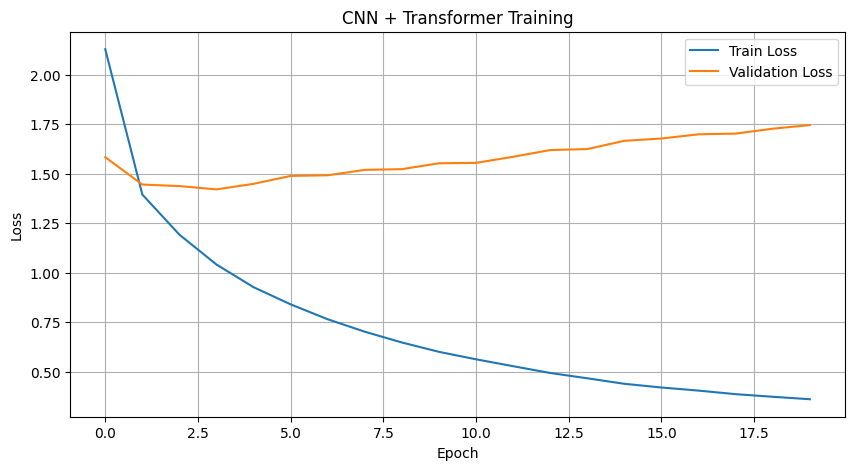

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN + Transformer Training")

plt.legend()
plt.grid()

plt.show()

In [74]:
model = CNNTransformer(
    vocab_size=len(tokenizer.word2idx),
    encoder_dim=2048,
    d_model=512,
    nhead=8,
    num_encoder_layers=3,
    num_decoder_layers=3,
    dim_feedforward=2048,
    dropout=0.1
).to(device)

model.load_state_dict(
    torch.load(
        "best_transformer_model.pth",
        map_location=device
    )
)

model.eval()

print("Đã tải mô hình CNN + Transformer!")

Đã tải mô hình CNN + Transformer!


In [75]:
def generate_caption_transformer(
    model,
    image,
    tokenizer,
    device,
    max_length=30
):
    model.eval()

    with torch.no_grad():

        # Thêm chiều batch
        image = image.unsqueeze(0).to(device)

        # Trích xuất đặc trưng ảnh
        features = model.cnn_encoder(image)

        features = model.projection(features)

        features = model.image_positional_encoding(features)

        encoded_features = model.transformer_encoder(features)

        # Bắt đầu bằng token <start>
        start_id = tokenizer.word2idx["<start>"]
        end_id = tokenizer.word2idx["<end>"]

        generated_ids = [start_id]

        for _ in range(max_length):

            # Chuyển danh sách token thành tensor
            captions = torch.tensor(
                [generated_ids],
                dtype=torch.long,
                device=device
            )

            # Dự đoán từ tiếp theo
            outputs = model.transformer_decoder(
                captions,
                encoded_features,
                tokenizer.word2idx["<pad>"]
            )

            # Lấy dự đoán tại vị trí cuối cùng
            next_token_logits = outputs[:, -1, :]

            next_word_id = next_token_logits.argmax(dim=-1).item()

            # Dừng khi gặp <end>
            if next_word_id == end_id:
                break

            generated_ids.append(next_word_id)

    # Bỏ <start> trước khi giải mã
    caption = tokenizer.decode(generated_ids[1:])

    return caption

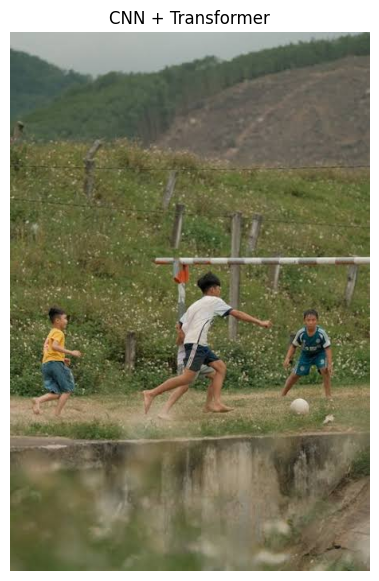

Caption dự đoán: một cậu bé đang xoay người để đánh_quả bóng_chày .


In [76]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = "/kaggle/input/datasets/bactx1607/test-image/test_images.jpg"

image = Image.open(image_path).convert("RGB")

image_tensor = image_transform(image)

caption = generate_caption_transformer(
    model,
    image_tensor,
    tokenizer,
    device
)

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.axis("off")
plt.title("CNN + Transformer")
plt.show()

print("Caption dự đoán:", caption)

In [77]:
image_folder = "/kaggle/working/uit_viic_images"

predictions = {}

model.eval()

for image_name in references.keys():

    image_path = os.path.join(image_folder, image_name)

    image = Image.open(image_path).convert("RGB")

    image_tensor = image_transform(image)

    caption = generate_caption_transformer(
        model,
        image_tensor,
        tokenizer,
        device,
        max_length=30
    )

    predictions[image_name] = caption

print("Đã dự đoán xong", len(predictions), "ảnh!")

Đã dự đoán xong 231 ảnh!


In [78]:
def metric_tokenize(text):
    text = text.lower().strip()
    text = ViTokenizer.tokenize(text)
    return text.split()

In [79]:
references_tokenized = {}
predictions_tokenized = {}

for image_name in references.keys():

    references_tokenized[image_name] = [
        metric_tokenize(caption)
        for caption in references[image_name]
    ]

    predictions_tokenized[image_name] = (
        metric_tokenize(predictions[image_name])
    )

Tính điểm BLEU

In [80]:
smooth = SmoothingFunction().method1

refs_bleu = []
preds_bleu = []

for image_name in references.keys():

    refs_bleu.append(
        references_tokenized[image_name]
    )

    preds_bleu.append(
        predictions_tokenized[image_name]
    )

bleu1 = corpus_bleu(
    refs_bleu,
    preds_bleu,
    weights=(1, 0, 0, 0),
    smoothing_function=smooth
)

bleu2 = corpus_bleu(
    refs_bleu,
    preds_bleu,
    weights=(0.5, 0.5, 0, 0),
    smoothing_function=smooth
)

bleu3 = corpus_bleu(
    refs_bleu,
    preds_bleu,
    weights=(1/3, 1/3, 1/3, 0),
    smoothing_function=smooth
)

bleu4 = corpus_bleu(
    refs_bleu,
    preds_bleu,
    weights=(0.25, 0.25, 0.25, 0.25),
    smoothing_function=smooth
)

print("BLEU-1:", round(bleu1, 4))
print("BLEU-2:", round(bleu2, 4))
print("BLEU-3:", round(bleu3, 4))
print("BLEU-4:", round(bleu4, 4))

BLEU-1: 0.6824
BLEU-2: 0.5353
BLEU-3: 0.4311
BLEU-4: 0.3439


Tính điểm CIDEr

In [81]:
gts = {}
res = {}

for idx, image_name in enumerate(references.keys()):

    image_id = str(idx)

    gts[image_id] = [
        " ".join(caption)
        for caption in references_tokenized[image_name]
    ]

    res[image_id] = [
        " ".join(predictions_tokenized[image_name])
    ]

cider_scorer = Cider()

cider_score, cider_scores = cider_scorer.compute_score(
    gts,
    res
)

print("CIDEr:", round(cider_score, 4))

CIDEr: 0.8885


# Mô hình CLIP tìm kiếm hình ảnh bằng câu mô tả tiếng Việt

In [88]:
import torch
import glob
import os

from PIL import Image
from sentence_transformers import SentenceTransformer, util

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Thiết bị đang sử dụng:", device)

Thiết bị đang sử dụng: cuda


Tải 2 thành phần của clip

In [112]:
from sentence_transformers import SentenceTransformer

# Encode ẢNH: CLIP gốc
image_model = SentenceTransformer('clip-ViT-B-32', device=device)

# Encode CÂU TIẾNG VIỆT: text encoder đa ngữ, được distill để khớp với CLIP gốc
text_model = SentenceTransformer('clip-ViT-B-32-multilingual-v1', device=device)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

In [109]:
import glob
import os

image_paths = sorted(
    glob.glob("/kaggle/working/uit_viic_images/*")
)

print("Tổng số ảnh:", len(image_paths))

Tổng số ảnh: 3850


Trích xuất vector ảnh theo batch

In [113]:
from PIL import Image
from tqdm.auto import tqdm
import torch

image_embeddings = []
valid_image_paths = []

batch_size = 32

for i in tqdm(range(0, len(image_paths), batch_size)):

    batch_paths = image_paths[i:i + batch_size]

    batch_images = []

    for path in batch_paths:
        try:
            image = Image.open(path).convert("RGB")
            batch_images.append(image)
            valid_image_paths.append(path)
        except Exception as e:
            print("Không đọc được ảnh:", path)

    if len(batch_images) > 0:
        embeddings = image_model.encode(
            batch_images,
            convert_to_tensor=True,
            normalize_embeddings=True,
            show_progress_bar=False
        )

        image_embeddings.append(embeddings.cpu())

# Ghép tất cả vector thành một tensor
image_embeddings = torch.cat(image_embeddings, dim=0)

print("Hoàn thành trích xuất vector!")
print("Kích thước:", image_embeddings.shape)
print("Số ảnh hợp lệ:", len(valid_image_paths))

  0%|          | 0/121 [00:00<?, ?it/s]

Hoàn thành trích xuất vector!
Kích thước: torch.Size([3850, 512])
Số ảnh hợp lệ: 3850


In [115]:
import json

# Lưu vector ảnh
torch.save(
    image_embeddings,
    "/kaggle/working/image_embeddings.pt"
)

# Lưu đường dẫn tương ứng với từng vector
with open(
    "/kaggle/working/image_paths.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(valid_image_paths, f, ensure_ascii=False, indent=2)

print("Đã lưu vector và danh sách đường dẫn ảnh!")

Đã lưu vector và danh sách đường dẫn ảnh!


**Xây dựng chức năng tìm kiếm ảnh bằng câu tiếng Việt.**

In [133]:
import torch
import json

image_embeddings = torch.load(
    "/kaggle/working/image_embeddings.pt",
    map_location=device
)

with open(
    "/kaggle/working/image_paths.json",
    "r",
    encoding="utf-8"
) as f:
    image_paths = json.load(f)

image_embeddings = image_embeddings.to(device)

print("Số vector ảnh:", image_embeddings.shape)
print("Số đường dẫn ảnh:", len(image_paths))

Số vector ảnh: torch.Size([3850, 512])
Số đường dẫn ảnh: 3850


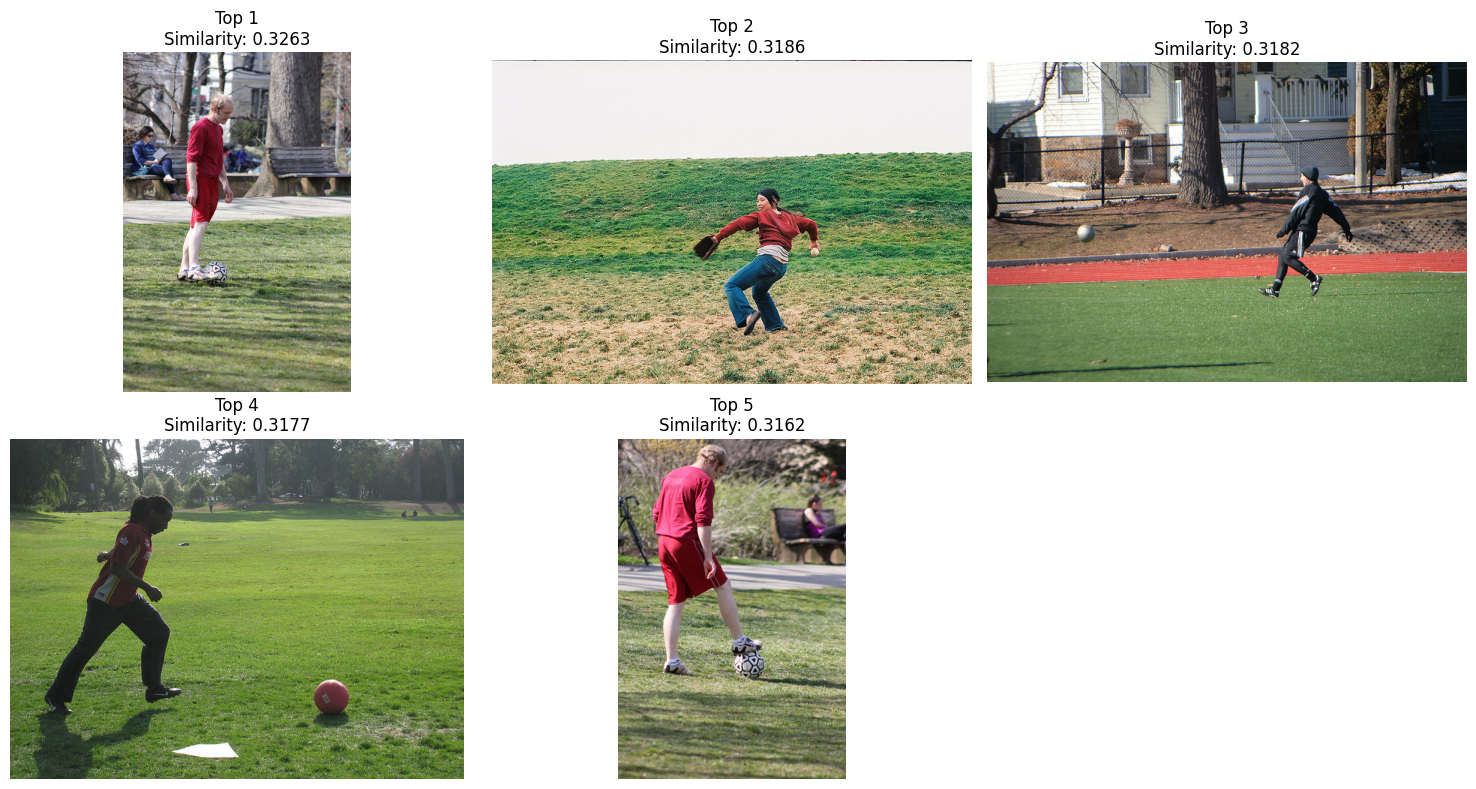

In [148]:
from sentence_transformers import util
from PIL import Image
import matplotlib.pyplot as plt
import math

def search_images(query, top_k=5):

    # Bước 1: Mã hóa câu tiếng Việt thành vector
    text_embedding = text_model.encode(
        query,
        convert_to_tensor=True,
        normalize_embeddings=True
    )

    # Bước 2: Tính độ tương đồng với toàn bộ vector ảnh
    similarities = util.cos_sim(
        text_embedding,
        image_embeddings
    )[0]

    # Bước 3: Lấy Top-K ảnh có điểm tương đồng cao nhất
    scores, indices = torch.topk(
        similarities,
        k=min(top_k, len(image_paths))
    )

    # Bước 4: Hiển thị kết quả
    plt.figure(figsize=(15, 4 * math.ceil(len(indices) / 3)))

    for i, (score, idx) in enumerate(zip(scores, indices)):

        image_path = image_paths[idx.item()]
        image = Image.open(image_path).convert("RGB")

        plt.subplot(math.ceil(len(indices) / 3), 3, i + 1)
        plt.imshow(image)
        plt.axis("off")

        plt.title(
            f"Top {i+1}\nSimilarity: {score.item():.4f}"
        )

    plt.tight_layout()
    plt.show()

    return [
        {
            "image_path": image_paths[idx.item()],
            "similarity": score.item()
        }
        for score, idx in zip(scores, indices)
    ]

query = "Một người đàn ông đang chơi bóng đá trên sân cỏ"

results = search_images(query, top_k=5)

In [149]:
import json

with open(
    "/kaggle/working/test_pairs.json",
    "r",
    encoding="utf-8"
) as f:
    test_pairs = json.load(f)

print("Số lượng mẫu:", len(test_pairs))
print("Mẫu đầu tiên:")
print(test_pairs[0])

Số lượng mẫu: 1155
Mẫu đầu tiên:
{'image_id': 205086, 'image': '000000205086.jpg', 'caption': 'Một cậu bé đang chống đẩy trên quả banh.'}


In [151]:
import os

# Ánh xạ tên ảnh -> vị trí vector tương ứng
image_to_index = {
    os.path.basename(path): idx
    for idx, path in enumerate(image_paths)
}

# Kiểm tra các ảnh trong tập test có tồn tại trong kho vector không
missing_images = [
    item["image"]
    for item in test_pairs
    if item["image"] not in image_to_index
]

print("Số caption test:", len(test_pairs))
print("Số ảnh không tìm thấy:", len(missing_images))

if missing_images:
    print("Một số ảnh bị thiếu:", missing_images[:5])
else:
    print("Tất cả ảnh test đều có vector tương ứng!")

Số caption test: 1155
Số ảnh không tìm thấy: 0
Tất cả ảnh test đều có vector tương ứng!


In [152]:
# Lấy danh sách caption
test_captions = [
    item["caption"]
    for item in test_pairs
]

# Mã hóa caption bằng Text Encoder
text_embeddings = text_model.encode(
    test_captions,
    batch_size=32,
    convert_to_tensor=True,
    normalize_embeddings=True,
    show_progress_bar=True
)

print("Kích thước vector câu truy vấn:", text_embeddings.shape)

Batches:   0%|          | 0/37 [00:00<?, ?it/s]

Kích thước vector câu truy vấn: torch.Size([1155, 512])


In [153]:
# Đưa vector ảnh về cùng thiết bị
image_embeddings = image_embeddings.to(device)

# Tính độ tương đồng giữa 1155 câu và 3850 ảnh
similarity_matrix = torch.matmul(
    text_embeddings,
    image_embeddings.T
)

print("Kích thước ma trận:", similarity_matrix.shape)

Kích thước ma trận: torch.Size([1155, 3850])


In [154]:
ranks = []

for i, item in enumerate(test_pairs):

    # Lấy vị trí vector của ảnh gốc
    target_idx = image_to_index[item["image"]]

    # Điểm tương đồng của ảnh gốc với câu truy vấn
    target_score = similarity_matrix[i, target_idx]

    # Đếm số ảnh có điểm cao hơn ảnh gốc
    rank = 1 + (similarity_matrix[i] > target_score).sum().item()

    ranks.append(rank)

print("Đã tính xong thứ hạng cho", len(ranks), "truy vấn")
print("5 thứ hạng đầu tiên:", ranks[:5])

Đã tính xong thứ hạng cho 1155 truy vấn
5 thứ hạng đầu tiên: [103, 28, 20, 51, 31]


In [158]:
import numpy as np

ranks = np.array(ranks)

# Recall@K
recall_at_1 = np.mean(ranks <= 1)
recall_at_5 = np.mean(ranks <= 5)
recall_at_10 = np.mean(ranks <= 10)

# Mean Reciprocal Rank
mrr = np.mean(1.0 / ranks)

print("===== KẾT QUẢ ĐÁNH GIÁ IMAGE RETRIEVAL =====")
print(f"Recall@1:  {recall_at_1:.4f} ({recall_at_1 * 100:.2f}%)")
print(f"Recall@5:  {recall_at_5:.4f} ({recall_at_5 * 100:.2f}%)")
print(f"Recall@10: {recall_at_10:.4f} ({recall_at_10 * 100:.2f}%)")
print(f"MRR:       {mrr:.4f}")

===== KẾT QUẢ ĐÁNH GIÁ IMAGE RETRIEVAL =====
Recall@1:  0.0416 (4.16%)
Recall@5:  0.0883 (8.83%)
Recall@10: 0.1108 (11.08%)
MRR:       0.0685
